# **Tree Planting Priority Analysis in Jeddah**


---


Overview:

This notebook analyzes vegetation (NDVI) and land surface temperature (LST)
using Sentinel Hub satellite data. It combines these indicators with
demographic and urban features, and applies machine learning models
(clustering and classification) to prioritize neighborhoods in Jeddah
for tree planting.


In [ ]:
!pip install sentinelhub folium seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 243.4/243.4 kB 22.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.6/165.6 kB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.1/250.1 kB 22.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.9/50.9 kB 5.0 MB/s eta 0:00:00


In [ ]:
# Sentinel Hub credentials are read from environment variables.
# Set them before running:  export SH_CLIENT_ID=...  and  export SH_CLIENT_SECRET=...
import os
assert os.environ.get("SH_CLIENT_ID") and os.environ.get("SH_CLIENT_SECRET"), "Set SH_CLIENT_ID and SH_CLIENT_SECRET"


In [ ]:
from sentinelhub import SHConfig

config = SHConfig()
print("Secret exists:", config.sh_client_secret is not None)

In [ ]:
#  Part 1: Import Libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import folium


from sentinelhub import (
    SHConfig, SentinelHubRequest, DataCollection, MimeType, BBox, CRS
)

from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import LabelEncoder

#  Part 2: Sentinel Hub Configuration
from sentinelhub import SHConfig

config = SHConfig()
config.sh_client_id = os.environ["SH_CLIENT_ID"]
config.sh_client_secret = os.environ["SH_CLIENT_SECRET"]


# Analysis of 4 Neighborhoods

In [ ]:
#  Part 3: Define Neighborhood Boundaries
# Define approximate bounding boxes for selected neighborhoods in Jeddah.
neighborhoods = {
    "Al Hamdaniyah": BBox([39.25, 21.75, 39.35, 21.85], crs=CRS.WGS84),
    "Abhur North":   BBox([39.10, 21.80, 39.20, 21.90], crs=CRS.WGS84),
    "Abhur South":   BBox([39.10, 21.70, 39.20, 21.80], crs=CRS.WGS84),
    "Al Basateen":   BBox([39.15, 21.65, 39.25, 21.75], crs=CRS.WGS84)
}

In [ ]:
#  Part 4: Define EvalScripts for NDVI and LST
# These scripts tell Sentinel Hub how to compute NDVI and LST from imagery.
ndvi_evalscript = """
//VERSION=3
function setup() {
  return { input: ["B04", "B08"], output: { bands: 1 } };
}
function evaluatePixel(s) {
  return [(s.B08 - s.B04) / (s.B08 + s.B04)];
}
"""

lst_evalscript = """
//VERSION=3
function setup() {
  return { input: ["B10"], output: { bands: 1, sampleType: "FLOAT32" } };
}
function evaluatePixel(s) {
  let temp_c = s.B10 - 273.15;
  return [temp_c];
}
"""

In [ ]:
#Part 5: Data Extraction Function
# A helper function that fetches satellite data from Sentinel Hub and
# computes the mean value for a neighborhood.
def get_mean_value(evalscript, data_collection, bbox, time_interval):
    request = SentinelHubRequest(
        evalscript=evalscript,
        input_data=[SentinelHubRequest.input_data(
            data_collection=data_collection,
            time_interval=time_interval
        )],
        responses=[SentinelHubRequest.output_response("default", MimeType.TIFF)],
        bbox=bbox,
        size=(64, 64),
        config=config
    )
    data = request.get_data()
    arr = np.array(data[0])
    arr = arr[arr != 0]
    return float(np.mean(arr)) if arr.size > 0 else np.nan

In [ ]:
# Part 6a: Compute NDVI and LST for Each Neighborhood
# Collect NDVI and LST averages for all neighborhoods over a given time interval.
time_interval = ("2024-05-15", "2024-06-15")

results = []
for name, bbox in neighborhoods.items():
    ndvi = get_mean_value(ndvi_evalscript, DataCollection.SENTINEL2_L2A, bbox, time_interval)
    lst  = get_mean_value(lst_evalscript, DataCollection.LANDSAT_OT_L2, bbox, time_interval)
    results.append({"Neighborhood": name, "Mean_NDVI": ndvi, "Mean_LST_C": lst})

df = pd.DataFrame(results)

 Raw Satellite Data for 4 Neighborhoods:
    Neighborhood  Mean_NDVI  Mean_LST_C
0  Al Hamdaniyah  15.390663   52.959579
1    Abhur North  19.389108   53.114174
2    Abhur South  21.505722   51.239670
3    Al Basateen  20.350649   52.747910


/tmp/ipython-input-1889115489.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="Neighborhood", y="Mean_NDVI", ax=axes[0], palette="Greens")
/tmp/ipython-input-1889115489.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30)
/tmp/ipython-input-1889115489.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="Neighborhood", y="Mean_LST_C", ax=axes[1], palette="Reds")
/tmp/ipython-input-1889115489.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLoca

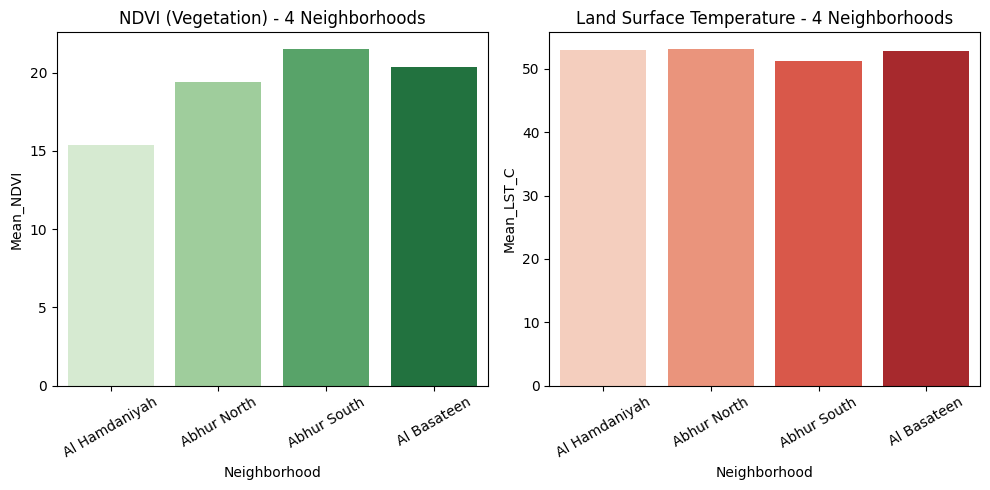

In [ ]:
# Part 6b: Analysis of 4 Neighborhoods
print(" Raw Satellite Data for 4 Neighborhoods:")
print(df[["Neighborhood","Mean_NDVI","Mean_LST_C"]])

# Plot NDVI & LST for 4 neighborhoods
fig, axes = plt.subplots(1,2, figsize=(10,5))
sns.barplot(data=df, x="Neighborhood", y="Mean_NDVI", ax=axes[0], palette="Greens")
axes[0].set_title("NDVI (Vegetation) - 4 Neighborhoods")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30)

sns.barplot(data=df, x="Neighborhood", y="Mean_LST_C", ax=axes[1], palette="Reds")
axes[1].set_title("Land Surface Temperature - 4 Neighborhoods")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30)
plt.tight_layout()
plt.show()


# **Expanding the area**


# Analysis of 14 Neighborhoods

In [ ]:
#  Part 7a: Expanded Neighborhoods for Jeddah
# Approximate bounding boxes (BBox) for 14 neighborhoods
neighborhoods_expanded = {
        "Al Hamdaniyah": BBox([39.25, 21.75, 39.35, 21.85], crs=CRS.WGS84),
    "Al Basateen":   BBox([39.13, 21.61, 39.20, 21.67], crs=CRS.WGS84),
    "Abhur North":   BBox([39.10, 21.80, 39.20, 21.90], crs=CRS.WGS84),
    "Abhur South":   BBox([39.10, 21.70, 39.20, 21.80], crs=CRS.WGS84),
    "Al Shati":      BBox([39.10, 21.55, 39.20, 21.65], crs=CRS.WGS84),
    "Al Salama":     BBox([39.15, 21.55, 39.25, 21.65], crs=CRS.WGS84),
    "Al Naeem":      BBox([39.20, 21.55, 39.30, 21.65], crs=CRS.WGS84),
    "Al Safa":       BBox([39.20, 21.50, 39.30, 21.60], crs=CRS.WGS84),
    "Al Rawdah":     BBox([39.15, 21.50, 39.25, 21.60], crs=CRS.WGS84),
    "Al Aziziyah":   BBox([39.20, 21.45, 39.30, 21.55], crs=CRS.WGS84),
    "Al Balad":      BBox([39.15, 21.45, 39.25, 21.55], crs=CRS.WGS84),
    "Ghulail":       BBox([39.15, 21.40, 39.25, 21.50], crs=CRS.WGS84),
    "Al Hindawiyah": BBox([39.20, 21.40, 39.30, 21.50], crs=CRS.WGS84),
    "Al Faisaliyah": BBox([39.25, 21.45, 39.35, 21.55], crs=CRS.WGS84)
}

time_interval = ("2024-05-15", "2024-06-15")

results = []
for name, bbox in neighborhoods_expanded.items():
    ndvi = get_mean_value(ndvi_evalscript, DataCollection.SENTINEL2_L2A, bbox, time_interval)
    lst  = get_mean_value(lst_evalscript, DataCollection.LANDSAT_OT_L2, bbox, time_interval)
    results.append({"Neighborhood": name, "Mean_NDVI": ndvi, "Mean_LST_C": lst})
df_all = pd.DataFrame(results)


 Raw Satellite Data for 14 Neighborhoods:
     Neighborhood  Mean_NDVI  Mean_LST_C
0   Al Hamdaniyah  15.390663   52.959579
1     Al Basateen  22.642967   49.997849
2     Abhur North  19.389108   53.114174
3     Abhur South  21.505722   51.239670
4        Al Shati  25.361946   47.319153
5       Al Salama  22.138949   50.031769
6        Al Naeem  20.520821   51.140263
7         Al Safa  23.041480   51.102867
8       Al Rawdah  24.040900   49.345932
9     Al Aziziyah  22.640260   51.581951
10       Al Balad  23.779279   48.782280
11        Ghulail  23.945359   47.030346
12  Al Hindawiyah  21.719595   51.394173
13  Al Faisaliyah  21.665539   52.273155


/tmp/ipython-input-2611809745.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_all, x="Neighborhood", y="Mean_NDVI", ax=axes[0], palette="Greens")
/tmp/ipython-input-2611809745.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=90)
/tmp/ipython-input-2611809745.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_all, x="Neighborhood", y="Mean_LST_C", ax=axes[1], palette="Reds")
/tmp/ipython-input-2611809745.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a F

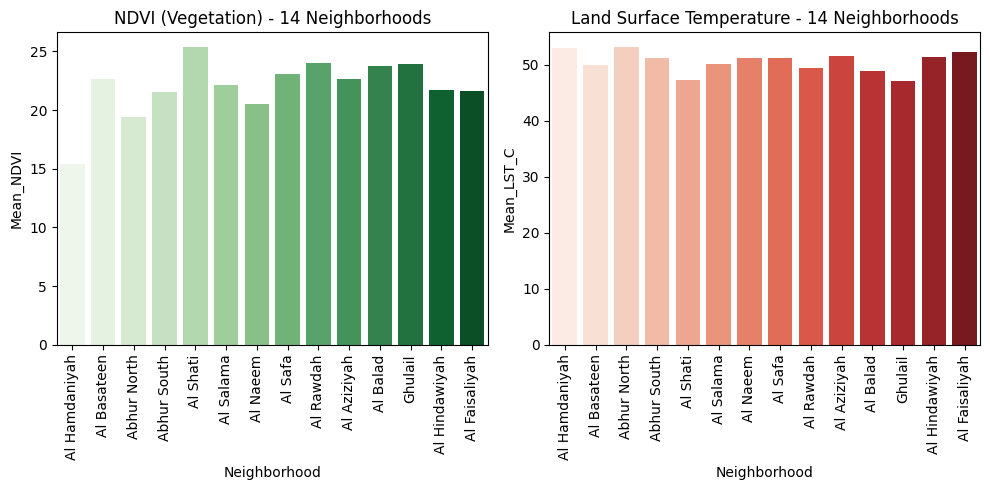

In [ ]:
#  Part 7b: Analysis of 14 Neighborhoods
print(" Raw Satellite Data for 14 Neighborhoods:")
print(df_all[["Neighborhood","Mean_NDVI","Mean_LST_C"]])

# Plot NDVI & LST for 14 neighborhoods
fig, axes = plt.subplots(1,2, figsize=(10,5))
sns.barplot(data=df_all, x="Neighborhood", y="Mean_NDVI", ax=axes[0], palette="Greens")
axes[0].set_title("NDVI (Vegetation) - 14 Neighborhoods")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=90)

sns.barplot(data=df_all, x="Neighborhood", y="Mean_LST_C", ax=axes[1], palette="Reds")
axes[1].set_title("Land Surface Temperature - 14 Neighborhoods")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=90)
plt.tight_layout()
plt.show()

 Priority Score Results:
     Neighborhood  Mean_NDVI  Mean_LST_C  Priority_Score Priority_Label_Score
0   Al Hamdaniyah  15.390663   52.959579       32.754507                 High
1     Al Basateen  22.642967   49.997849       28.505604                  Low
2     Abhur North  19.389108   53.114174       31.663189                 High
3     Abhur South  21.505722   51.239670       29.716052               Medium
4        Al Shati  25.361946   47.319153       25.814823                  Low
5       Al Salama  22.138949   50.031769       28.680553               Medium
6        Al Naeem  20.520821   51.140263       29.941937                 High
7         Al Safa  23.041480   51.102867       29.159563               Medium
8       Al Rawdah  24.040900   49.345932       27.629882                  Low
9     Al Aziziyah  22.640260   51.581951       29.615288               Medium
10       Al Balad  23.779279   48.782280       27.313812                  Low
11        Ghulail  23.945359   47.03034

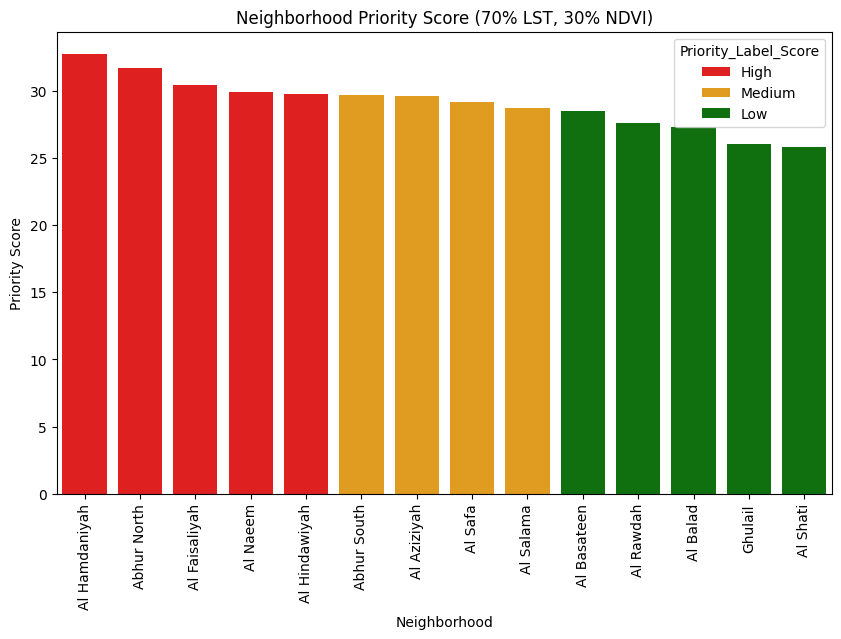

In [ ]:
#  Part 8: Priority Score (Simple Formula)
# Define a score where higher LST increases priority and higher NDVI decreases it
# Weight: 70% LST + 30% (1 - NDVI)
# helps to identify the classification labels (low , medium ,high ) for trainig the model
df_all["Priority_Score"] = (0.7 * df_all["Mean_LST_C"]) + (0.3 * (1 - df_all["Mean_NDVI"]))

# Divide neighborhoods into High / Medium / Low based on quantiles
quantiles = df_all["Priority_Score"].quantile([0.33, 0.66]).values
def assign_priority(score):
    if score <= quantiles[0]:
        return "Low"
    elif score <= quantiles[1]:
        return "Medium"
    else:
        return "High"

df_all["Priority_Label_Score"] = df_all["Priority_Score"].apply(assign_priority)

print(" Priority Score Results:")
print(df_all[["Neighborhood", "Mean_NDVI", "Mean_LST_C", "Priority_Score", "Priority_Label_Score"]])

# --- Visualization ---
plt.figure(figsize=(10,6))
sns.barplot(
    data=df_all.sort_values("Priority_Score", ascending=False),
    x="Neighborhood", y="Priority_Score", hue="Priority_Label_Score",
    dodge=False, palette={"High":"red","Medium":"orange","Low":"green"}
)
plt.title("Neighborhood Priority Score (70% LST, 30% NDVI)")
plt.xticks(rotation=90)
plt.ylabel("Priority Score")
plt.show()


# `ML PART`

# Random Forest with Cross Validation on 14 neighborhood



/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(


 Cross Validation Accuracy (14 neighborhoods): 0.93


/tmp/ipython-input-299082583.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=importances, y=["NDVI","LST"], palette="coolwarm")


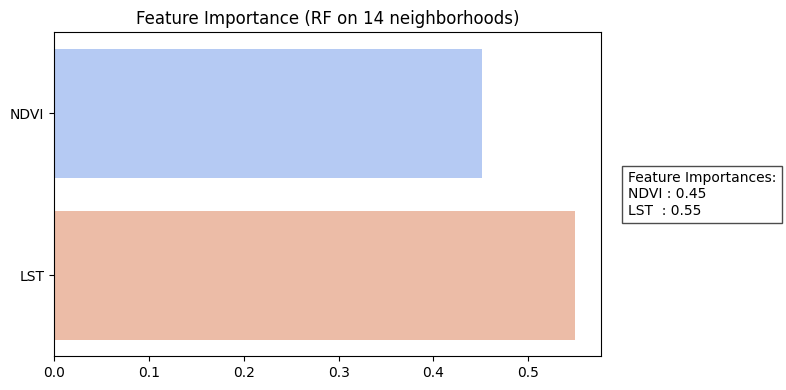

In [ ]:
 # Part 9: Random Forest with Cross Validation (14 neighborhoods)
# Simple labeling rule for training
labels = []
for _, row in df_all.iterrows():
    if row["Mean_LST_C"] > 50 and row["Mean_NDVI"] < 0.25:
        labels.append("High")
    elif row["Mean_LST_C"] < 48 and row["Mean_NDVI"] > 0.3:
        labels.append("Low")
    else:
        labels.append("Medium")
df_all["Priority_Label_RF"] = labels

# Encode
X = df_all[["Mean_NDVI","Mean_LST_C"]]
y = LabelEncoder().fit_transform(df_all["Priority_Label_RF"])

model = RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42)
scores = cross_val_score(model, X, y, cv=5)
print(" Cross Validation Accuracy (14 neighborhoods):", np.mean(scores).round(2))

model.fit(X, y)
importances = model.feature_importances_

# Plot Feature Importances
plt.figure(figsize=(8,4))

ax = sns.barplot(x=importances, y=["NDVI","LST"], palette="coolwarm")
plt.title("Feature Importance (RF on 14 neighborhoods)")

table_text = f"Feature Importances:\n" \
             f"NDVI : {importances[0]:.2f}\n" \
             f"LST  : {importances[1]:.2f}"

plt.gca().text(1.05, 0.5, table_text, transform=plt.gca().transAxes,
               fontsize=10, verticalalignment='center',
               bbox=dict(facecolor='white', alpha=0.7))

plt.tight_layout()
plt.show()


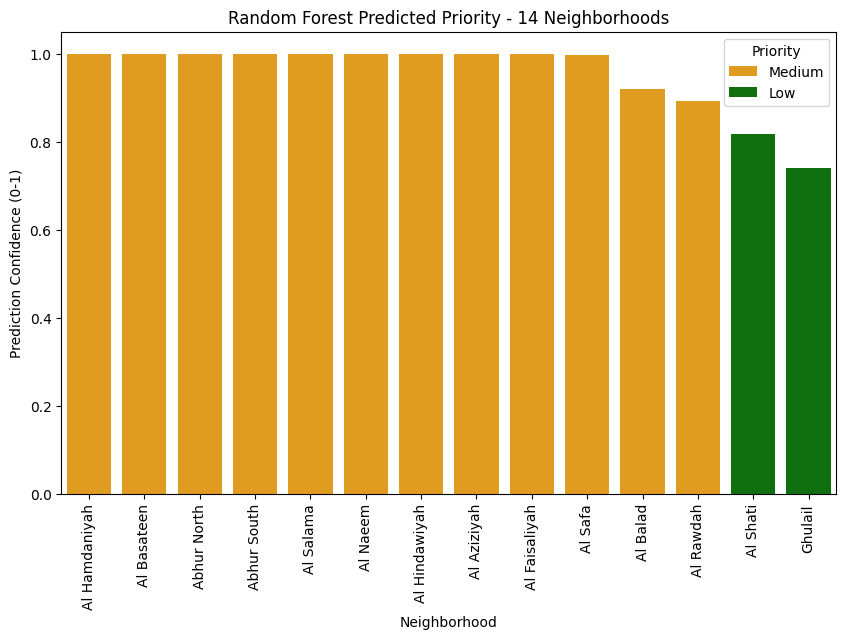

In [ ]:
from sklearn.preprocessing import LabelEncoder

#  Train Random Forest on the 14 neighborhoods
model.fit(X, y)

# Predict priority labels
preds = model.predict(X)
encoder = LabelEncoder().fit(df_all["Priority_Label_RF"])
df_all["RF_Priority_Label"] = encoder.inverse_transform(preds)

# Prediction confidence (max probability per row)
proba = model.predict_proba(X).max(axis=1)
df_all["RF_Priority_Score"] = proba

#  Bar Plot (Random Forest Priority)
plt.figure(figsize=(10,6))
sns.barplot(
    data=df_all.sort_values("RF_Priority_Score", ascending=False),
    x="Neighborhood",
    y="RF_Priority_Score",
    hue="RF_Priority_Label",
    dodge=False,
    palette={"High":"red","Medium":"orange","Low":"green"}
)
plt.title("Random Forest Predicted Priority - 14 Neighborhoods")
plt.ylabel("Prediction Confidence (0-1)")
plt.xticks(rotation=90)
plt.legend(title="Priority")
plt.show()


In [ ]:

#  Folium Map (colored by RF Priority)
colors_map_rf = {"High":"red","Medium":"orange","Low":"green"}

m14 = folium.Map(location=[21.50, 39.20], zoom_start=11)
for i,row in df_all.iterrows():
    bbox = neighborhoods_expanded[row["Neighborhood"]]
    center_lat = (bbox.min_y + bbox.max_y) / 2
    center_lon = (bbox.min_x + bbox.max_x) / 2
    folium.CircleMarker(
        location=[center_lat, center_lon],
        radius=8,
        color=colors_map_rf[row["RF_Priority_Label"]],
        fill=True,
        fill_opacity=0.7,
        popup=f"{row['Neighborhood']} - Priority: {row['RF_Priority_Label']} (Conf: {row['RF_Priority_Score']:.2f})"
    ).add_to(m14)

m14.save("rf_priority_map.html")
m14


لخفض الحراره المكان المناسب لببي نزعره يساعد جده